In [ ]:
import pandas as pd

df = pd.read_csv("/content/healthcare_dataset.csv")
print(df.shape)

# Standardise column names
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Clean text columns
df["name"] = df["name"].str.strip().str.title()
df["doctor"] = df["doctor"].str.strip()
df["hospital"] = df["hospital"].str.strip().str.rstrip(",").str.strip()

# Duplicates
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

# Dates
df["date_of_admission"] = pd.to_datetime(df["date_of_admission"])
df["discharge_date"] = pd.to_datetime(df["discharge_date"])

# New columns
df["length_of_stay"] = (df["discharge_date"] - df["date_of_admission"]).dt.days
df["admission_month"] = df["date_of_admission"].dt.month_name()
df["admission_weekday"] = df["date_of_admission"].dt.day_name()
df["age_group"] = pd.cut(df["age"], bins=[0, 18, 35, 50, 65, 120],
                         labels=["0-18", "19-35", "36-50", "51-65", "65+"])
df["billing_amount"] = df["billing_amount"].round(2)

# Checks
print(df.isnull().sum())
print("Negative bills:", (df["billing_amount"] < 0).sum())
print("Stays <= 0 days:", (df["length_of_stay"] <= 0).sum())

# Save
df.to_csv("/content/cleaned_data.csv", index=False)
df.head()


(55500, 15)
Duplicates: 534
name                  0
age                   0
gender                0
blood_type            0
medical_condition     0
date_of_admission     0
doctor                0
hospital              0
insurance_provider    0
billing_amount        0
room_number           0
admission_type        0
discharge_date        0
medication            0
test_results          0
length_of_stay        0
admission_month       0
admission_weekday     0
age_group             0
dtype: int64
Negative bills: 106
Stays <= 0 days: 0


,name,age,gender,blood_type,medical_condition,date_of_admission,doctor,hospital,insurance_provider,billing_amount,room_number,admission_type,discharge_date,medication,test_results,length_of_stay,admission_month,admission_weekday,age_group
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,328,Urgent,2024-02-02,Paracetamol,Normal,2,January,Wednesday,19-35
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6,August,Tuesday,51-65
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.10,205,Emergency,2022-10-07,Aspirin,Normal,15,September,Thursday,65+
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,Hernandez Rogers and Vang,Medicare,37909.78,450,Elective,2020-12-18,Ibuprofen,Abnormal,30,November,Wednesday,19-35
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.32,458,Urgent,2022-10-09,Penicillin,Abnormal,20,September,Monday,36-50


In [ ]:
# Look at them
neg = df[df["billing_amount"] < 0]
print(neg[["medical_condition", "admission_type", "billing_amount"]].describe())
neg.head()

# Flag, then remove from the analysis dataset
df["negative_bill_flag"] = df["billing_amount"] < 0
df_clean = df[df["billing_amount"] >= 0].copy()

print("Rows before:", len(df), "| after:", len(df_clean))
df_clean.to_csv("/content/cleaned_data.csv", index=False)

       billing_amount
count      106.000000
mean      -502.472453
std        429.856785
min      -2008.490000
25%       -803.007500
50%       -374.840000
75%       -149.072500
max        -23.870000
Rows before: 54966 | after: 54860


**README**


*Removed 534 duplicate records.

*Standardised column names, patient name casing, and hospital name formatting.

*Converted dates to datetime and created length of stay, admission month, weekday, and age group.

*Removed 106 records with negative billing amount(invalid values).

*Validated that no stays were zero or negative.

Final dataset: about 54,860 rows.




# EDA

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("/content/cleaned_data.csv", parse_dates=["date_of_admission", "discharge_date"])
print(df.shape)
df.head()

(54860, 20)


,name,age,gender,blood_type,medical_condition,date_of_admission,doctor,hospital,insurance_provider,billing_amount,room_number,admission_type,discharge_date,medication,test_results,length_of_stay,admission_month,admission_weekday,age_group,negative_bill_flag
0,Bobby Jackson,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.28,328,Urgent,2024-02-02,Paracetamol,Normal,2,January,Wednesday,19-35,False
1,Leslie Terry,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.33,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6,August,Tuesday,51-65,False
2,Danny Smith,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.10,205,Emergency,2022-10-07,Aspirin,Normal,15,September,Thursday,65+,False
3,Andrew Watts,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,Hernandez Rogers and Vang,Medicare,37909.78,450,Elective,2020-12-18,Ibuprofen,Abnormal,30,November,Wednesday,19-35,False
4,Adrienne Bell,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.32,458,Urgent,2022-10-09,Penicillin,Abnormal,20,September,Monday,36-50,False


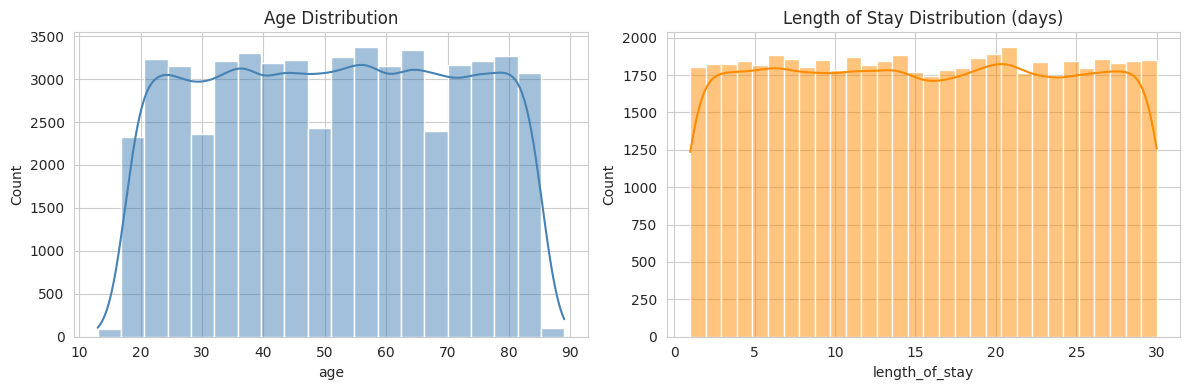

                age  length_of_stay
count  54860.000000    54860.000000
mean      51.533850       15.498815
std       19.605295        8.661357
min       13.000000        1.000000
25%       35.000000        8.000000
50%       52.000000       15.000000
75%       68.000000       23.000000
max       89.000000       30.000000


In [ ]:
#Histogram of age and length of stay
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["age"], bins=20, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Age Distribution")

sns.histplot(df["length_of_stay"], bins=30, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Length of Stay Distribution (days)")

plt.tight_layout()
plt.savefig("hist_age_los.png", dpi=150)
plt.show()

print(df[["age", "length_of_stay"]].describe())

# WHAT IT SAYS :

**Age**

 *Range: 13 to 89 years, so there are no children under
13 and no extreme outliers.

 *Mean 51.5, median 52: these are almost identical, so the distribution is roughly symmetric, not skewed.

 *Middle 50% of patients: between 35 and 68 years old.





**Length of stay**

 *Range: 1 to 30 days, with a mean of 15.5 and a median of 15.

 *Middle 50% of stays: between 8 and 23 days.

 *Standard deviation of 8.66: this is almost exactly what you'd get if stays were spread evenly between 1 and 30 days. So your histogram will probably look flat, not bell-shaped. This is another sign the data is synthetic (randomly generated), and it also means hospital stays here are unusually long compared to real hospitals. Check your histogram to confirm.

# INSIGHTS

Age: Patients range from 13 to 89 years old, with an average age of about 52. The age distribution is fairly balanced around the middle, and half of all patients are between 35 and 68 years old.

Length of stay: Hospital stays range from 1 to 30 days, averaging about 15.5 days. Stay lengths appear evenly spread across this range, with no dominant short or long stay pattern, so the hospital cannot assume a "typical" stay length for capacity planning.

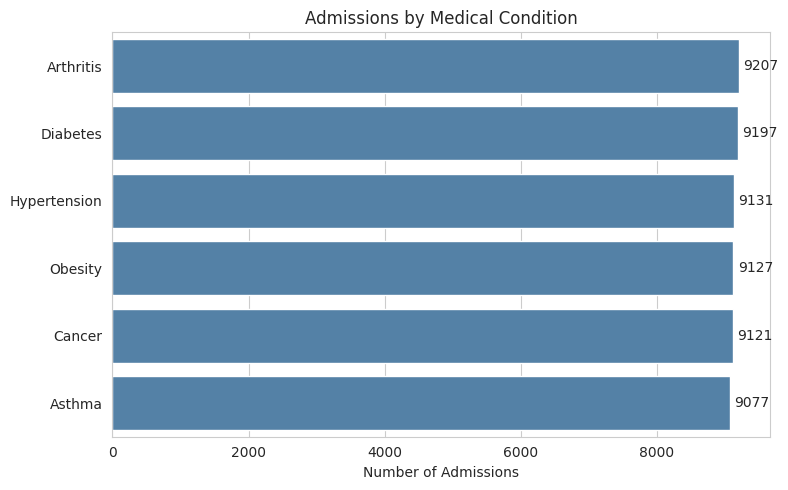

In [ ]:
#Bar chart of admissions by conditions
order = df["medical_condition"].value_counts().index

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, y="medical_condition", order=order, color="steelblue")
ax.bar_label(ax.containers[0], padding=3)
plt.title("Admissions by Medical Condition")
plt.xlabel("Number of Admissions")
plt.ylabel("")
plt.tight_layout()
plt.savefig("bar_condition.png", dpi=150)
plt.show()

In [ ]:
counts = df["medical_condition"].value_counts()
print(counts)
print((counts / counts.sum() * 100).round(1))

medical_condition
Arthritis       9207
Diabetes        9197
Hypertension    9131
Obesity         9127
Cancer          9121
Asthma          9077
Name: count, dtype: int64
medical_condition
Arthritis       16.8
Diabetes        16.8
Hypertension    16.6
Obesity         16.6
Cancer          16.6
Asthma          16.5
Name: count, dtype: float64


# WHAT IT SAYS

**Highest:** Arthritis with 9,207 admissions (16.8%).
Lowest: Asthma with 9,077 admissions (16.5%).

**Gap between highest and lowest:** 130 admissions, which is about 1.4% of the Asthma count and only 0.3 percentage points of the total.

**Even split would be:** 16.67% each (1/6), and every condition is within about 0.2 points of that.



# INSIGHTS

Admissions are spread almost evenly across the six medical conditions, with each accounting for roughly 16.5% to 16.8% of cases. Arthritis (9,207) and Diabetes (9,197) are marginally the most common, and Asthma (9,077) the least, but the 130-admission gap is too small to be meaningful. No single condition dominates hospital demand, so resource planning should treat all six conditions as similar in volume.

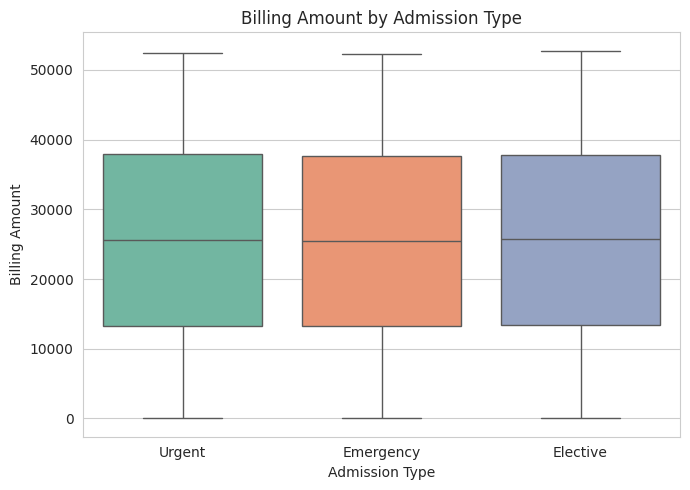

                    mean    median    min       max
admission_type                                     
Elective        25663.34  25706.75   9.24  52764.28
Emergency       25551.13  25465.12  23.73  52271.66
Urgent          25568.44  25595.59  31.03  52373.03


In [ ]:
#Boxplot of billing amount by admission type

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="admission_type", y="billing_amount",
            hue="admission_type", palette="Set2", legend=False)
plt.title("Billing Amount by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Billing Amount")
plt.tight_layout()
plt.savefig("box_billing.png", dpi=150)
plt.show()

print(df.groupby("admission_type")["billing_amount"].agg(["mean", "median", "min", "max"]).round(2))


# WHAT IT SAYS

**Means:** Elective 25,663, Urgent 25,568, Emergency 25,551. The gap between highest and lowest is about 112, or 0.4%.

**Medians:** Elective 25,707, Urgent 25,596, Emergency 25,465. The gap is about 242, or under 1%.

**Range:** Every type runs from nearly 0 (9 to 31) up to about 52,000, so the boxes will look almost identical in height and position.

Mean close to median in each group, so the distributions are roughly symmetric, and there are probably few or no outlier dots beyond the whiskers.

# INSIGHTS

Billing amounts are nearly identical across the three admission types. Average bills are about 25,550 to 25,660 for Elective, Urgent, and Emergency admissions, a difference of under 0.5%, and medians differ by less than 1%. Costs range widely within each type (from near zero to over 52,000), so admission type is not a meaningful driver of billing. Emergency admissions, which might be expected to cost more, are not more expensive in this dataset.

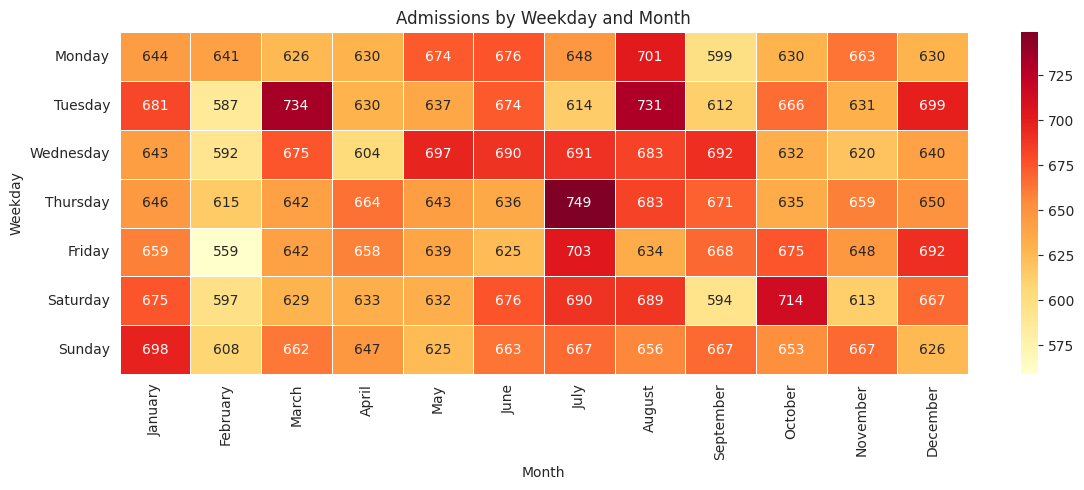

In [ ]:
#Heatmap of admissions by weekday and month

month_order = ["January","February","March","April","May","June","July",
               "August","September","October","November","December"]
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

pivot = pd.crosstab(df["admission_weekday"], df["admission_month"])
pivot = pivot.reindex(index=day_order, columns=month_order)

plt.figure(figsize=(12, 5))
sns.heatmap(pivot, annot=True, fmt="d", cmap="YlOrRd", linewidths=0.5)
plt.title("Admissions by Weekday and Month")
plt.xlabel("Month")
plt.ylabel("Weekday")
plt.tight_layout()
plt.savefig("heatmap_weekday_month.png", dpi=150)
plt.show()

# WHAT IT SAYS

**Busiest single cell:** Thursday in July (749), followed by Tuesday in March (734), Tuesday in August (731), and Saturday in October (714).

**Quietest single cell:** Friday in February (559), followed by Tuesday in February (587), Wednesday in February (592), and Saturday in September (594).

**Typical cell:** about 650 admissions (54,860 ÷ 84 cells), and most cells fall between 600 and 700.

**Weekdays:** The gap between the busiest and quietest day is only 134 admissions (about 1.7%). Weekends are as busy as weekdays.

**Months:** February stands out as the lowest, but it also has fewer days (28 or 29 versus 30 or 31). That alone explains about a 9% drop, which is roughly the size of the dip you see. So February isn't a genuinely quieter season.

**Individual hot cells:** Cells like Thursday-July (749) are interesting but small. Some of the variation comes from how many times a weekday occurs in a month, since a month has four or five of each weekday. Don't build a story on any one cell.

# INSIGHTS

Admissions are spread very evenly across weekdays, with totals ranging only from 7,762 (Monday) to 7,896 (Tuesday), a difference of under 2%. Weekends are as busy as weekdays, so staffing would not need a weekend reduction. Monthly volumes are also stable at roughly 4,500 to 4,780, with July and August the highest. February is the lowest (4,199), but this is largely because it has fewer days. The single busiest day-month combination is Thursday in July (749 admissions). Overall, there is no strong seasonal or weekly pattern.

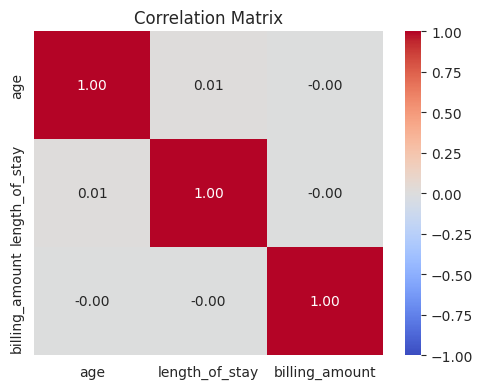

In [ ]:
#Correlation between age, length of stay, and billing

corr = df[["age", "length_of_stay", "billing_amount"]].corr()

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig("correlation.png", dpi=150)
plt.show()

# WHAT IT SAYS

Pair	 |   Correlation	    |      Meaning

Age and length of stay|	0.01	|No relationship

Age and billing amount|	-0.00|	No relationship

Length of stay and billing amount	|-0.00	|No relationship

The 1.00 values on the diagonal are just each variable compared with itself, so ignore them. Anything between -0.1 and 0.1 is negligible.

The length of stay vs. billing result is the most telling. In a real hospital, longer stays cost more, and you'd expect a clearly positive correlation (often 0.5 or higher). Here it's zero, so billing was almost certainly generated randomly, independent of everything else.

# INSIGHTS

Age, length of stay, and billing amount show no meaningful linear relationship. All pairwise correlations are between -0.01 and 0.01 (age vs. length of stay = 0.01; age vs. billing = 0.00; length of stay vs. billing = 0.00). Older patients do not stay longer or pay more, and longer stays do not lead to higher bills. This is unusual for real healthcare data, where length of stay typically drives cost, and it suggests the billing amounts in this dataset were generated independently of patient characteristics.

**insights summarise**

Age and stay length: Ages 13 to 89 (mean 52) and stays of 1 to 30 days (mean 15.5), with no dominant pattern.
Conditions: Six conditions split almost evenly (16.5% to 16.8% each).

Billing by admission type: Nearly identical costs across Elective, Urgent, and Emergency (under 0.5% difference).

Weekday and month: No meaningful weekly or seasonal pattern, and February's dip is mostly due to having fewer days.

Correlation: No relationship between age, stay length, and billing.

# What this means for your project


"The dataset appears to be synthetic: volumes are evenly distributed and costs are uncorrelated with age, stay length, or admission type. The project therefore demonstrates the end-to-end analytics workflow (cleaning, SQL, EDA, dashboarding) rather than producing real clinical conclusions."